# Perbandingan antar algoritma

Hasil dibaca dari `exp_results/runs/`. Setiap algoritma diwakili konfigurasi terbaiknya (peringkat 1 di notebook masing-masing).

## 0. Setup

In [1]:
import sys
from pathlib import Path

# cari root repo
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.paths import FIGURES_DIR, RUNS_DIR, TABLES_DIR
from src.problem import load_instances
from src.evaluation.runner import load_results
from src.evaluation.metrics import best_configs, rank_configs, runs_to_frame, save_table, summarize
from src.evaluation import plots

pd.set_option("display.width", 200, "display.max_columns", 40)

## 1. Pilihan optimum

In [2]:
from src.config import load_config

OPTIMUM = load_config()["optimum"]   # sama untuk semua notebook, dari configs/experiment.json
instances = load_instances(optimum=OPTIMUM)

## 2. Ranking semua konfigurasi

In [3]:
results = load_results(runs_dir=RUNS_DIR)
runs = runs_to_frame(results, instances, OPTIMUM)
summary = summarize(runs)
ranking = rank_configs(summary)
best = best_configs(ranking)

table_dir = TABLES_DIR / "comparison"
figure_dir = FIGURES_DIR / "comparison"
save_table(ranking, table_dir / "ranking_all.csv")

print("konfigurasi terbaik:", best)
ranking.round(5)

konfigurasi terbaik: {'genetic': 'sel_rank', 'random_search': 'batch_20', 'swarm': 'sigmoid_s20'}


,algorithm,config,rank,pct_feasible,pct_near_optimal,gap_mean,gap_max,pct_optimum_found,runtime_mean,iterations_to_best_mean,evaluations_to_best_mean
0,genetic,sel_rank,1,100.0,100.0,0.01192,0.04011,57.22222,0.07805,39.55556,1543.11111
1,genetic,pop_80,2,100.0,100.0,0.01279,0.03460,60.00000,0.07459,19.85000,1628.30000
2,genetic,sel_roulette,3,100.0,100.0,0.01386,0.04043,56.11111,0.07777,46.49444,1806.78889
3,genetic,default,4,100.0,100.0,0.01722,0.04553,51.66667,0.07579,37.21667,1454.23333
4,genetic,cx_two_point,5,100.0,100.0,0.01849,0.05919,50.00000,0.11254,35.95556,1406.31111
5,genetic,cx_one_point,6,100.0,100.0,0.01961,0.05243,48.33333,0.07727,32.97222,1292.94444
6,genetic,mut_swap,7,100.0,100.0,0.02617,0.10998,43.33333,0.05608,29.81667,1173.03333
7,genetic,pop_20,8,100.0,100.0,0.02704,0.07174,43.88889,0.08881,85.64444,1561.60000
8,random_search,batch_20,1,100.0,100.0,0.03557,0.07840,42.22222,0.01324,79.74444,1614.88889
9,random_search,batch_40,2,100.0,100.0,0.03557,0.07840,42.22222,0.00787,39.67778,1627.11111


## 3. Tabel perbandingan best config

In [4]:
is_best = lambda algo, config: best.get(algo) == config
best_results = [r for r in results if is_best(r.algorithm, r.config)]
best_runs = runs[[is_best(a, c) for a, c in zip(runs.algorithm, runs.config)]]
best_summary = summary[[is_best(a, c) for a, c in zip(summary.algorithm, summary.config)]]

save_table(best_runs, table_dir / "runs.csv")
save_table(best_summary, table_dir / "summary.csv")

best_summary.pivot_table(
    index="n_diesets",
    columns="algorithm",
    values=["pct_feasible", "pct_near_optimal", "cost_ratio_best", "gap_mean", "pct_optimum_found",
            "runtime_mean", "iterations_to_best_mean", "evaluations_to_best_mean"],
).round(5)

cost_ratio_best                     evaluations_to_best_mean                           gap_mean                        iterations_to_best_mean                          pct_feasible  \
algorithm         genetic random_search swarm                  genetic random_search       swarm  genetic random_search    swarm                 genetic random_search      swarm      genetic   
n_diesets                                                                                                                                                                                        
3                     1.0       1.00000   1.0                 40.00000      20.00000    20.00000  0.00000       0.00000  0.00000                 0.00000       0.00000    0.00000        100.0   
9                     1.0       1.00000   1.0                300.93333     567.33333   238.66667  0.00000       0.00000  0.00000                 6.86667      27.36667   10.93333        100.0   
13                    1.0       1.00000   1.0               1704.40000    2018.66667  2076.00000  0.00725       0.00767  0.00241                43.80000      99.93333  102.80000        100.0   
16                    1.0       1.00000   1.0               1820.93333    1983.33333  2880.00000  0.02204       0.06970  0.01796                46.86667      98.16667  143.00000        100.0   
18                    1.0       1.00007   1.0               2606.26667    2622.66667  3004.66667  0.00843       0.04121  0.01008                67.53333     130.13333  149.23333        100.0   
19                    1.0       1.00002   1.0               2786.13333    2477.33333  2312.00000  0.03381       0.09485  0.03076                72.26667     122.86667  114.60000        100.0   

                               pct_near_optimal                      pct_optimum_found                          runtime_mean                         
algorithm random_search  swarm          genetic random_search  swarm           genetic random_search      swarm      genetic random_search    swarm  
n_diesets                                                                                                                                            
3                 100.0  100.0            100.0         100.0  100.0         100.00000     100.00000  100.00000      0.07347       0.01237  0.01496  
9                 100.0  100.0            100.0         100.0  100.0         100.00000     100.00000  100.00000      0.07745       0.01319  0.01589  
13                100.0  100.0            100.0         100.0  100.0          83.33333      50.00000   90.00000      0.07782       0.01330  0.01692  
16                100.0  100.0            100.0         100.0  100.0          36.66667       3.33333   50.00000      0.07755       0.01338  0.01754  
18                100.0  100.0            100.0         100.0  100.0          16.66667       0.00000   10.00000      0.07775       0.01373  0.01767  
19                100.0  100.0            100.0         100.0  100.0           6.66667       0.00000   13.33333      0.08424       0.01346  0.01863

## 4. Plot antar algoritma

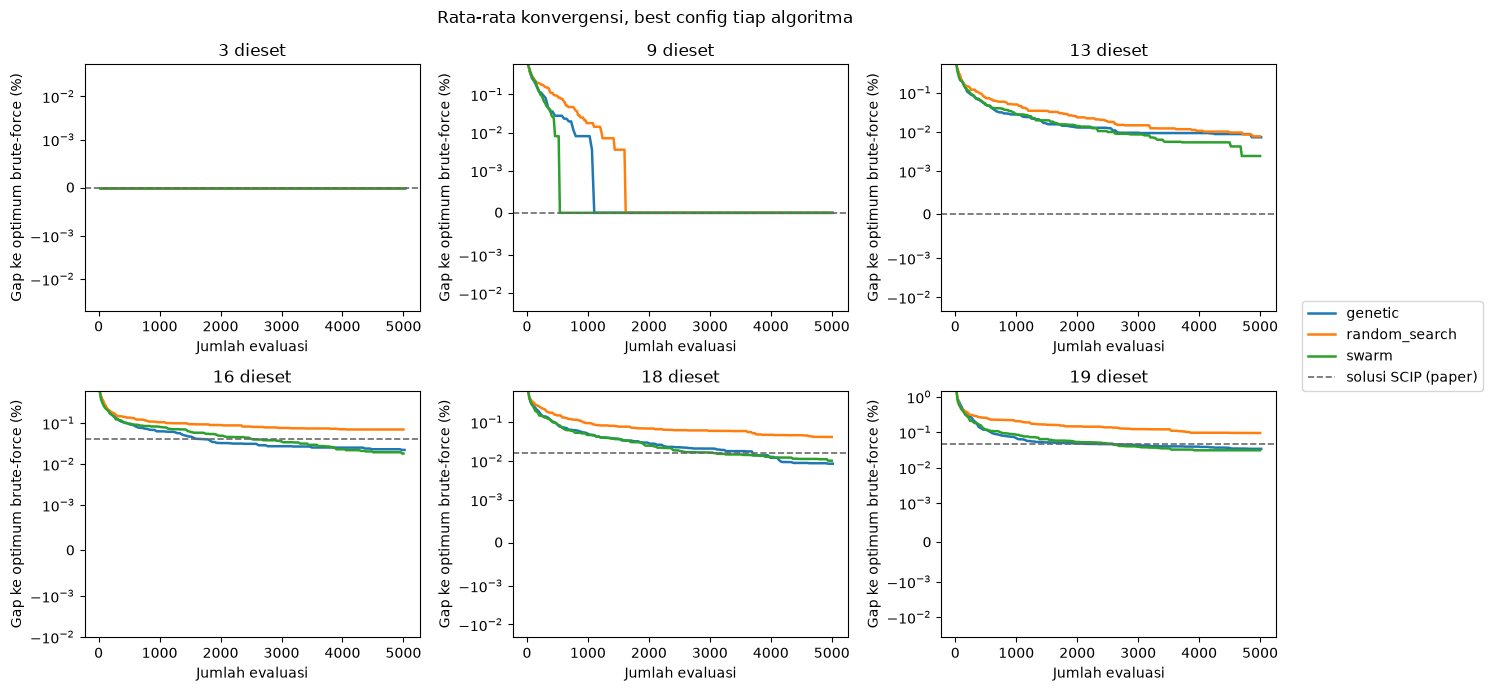

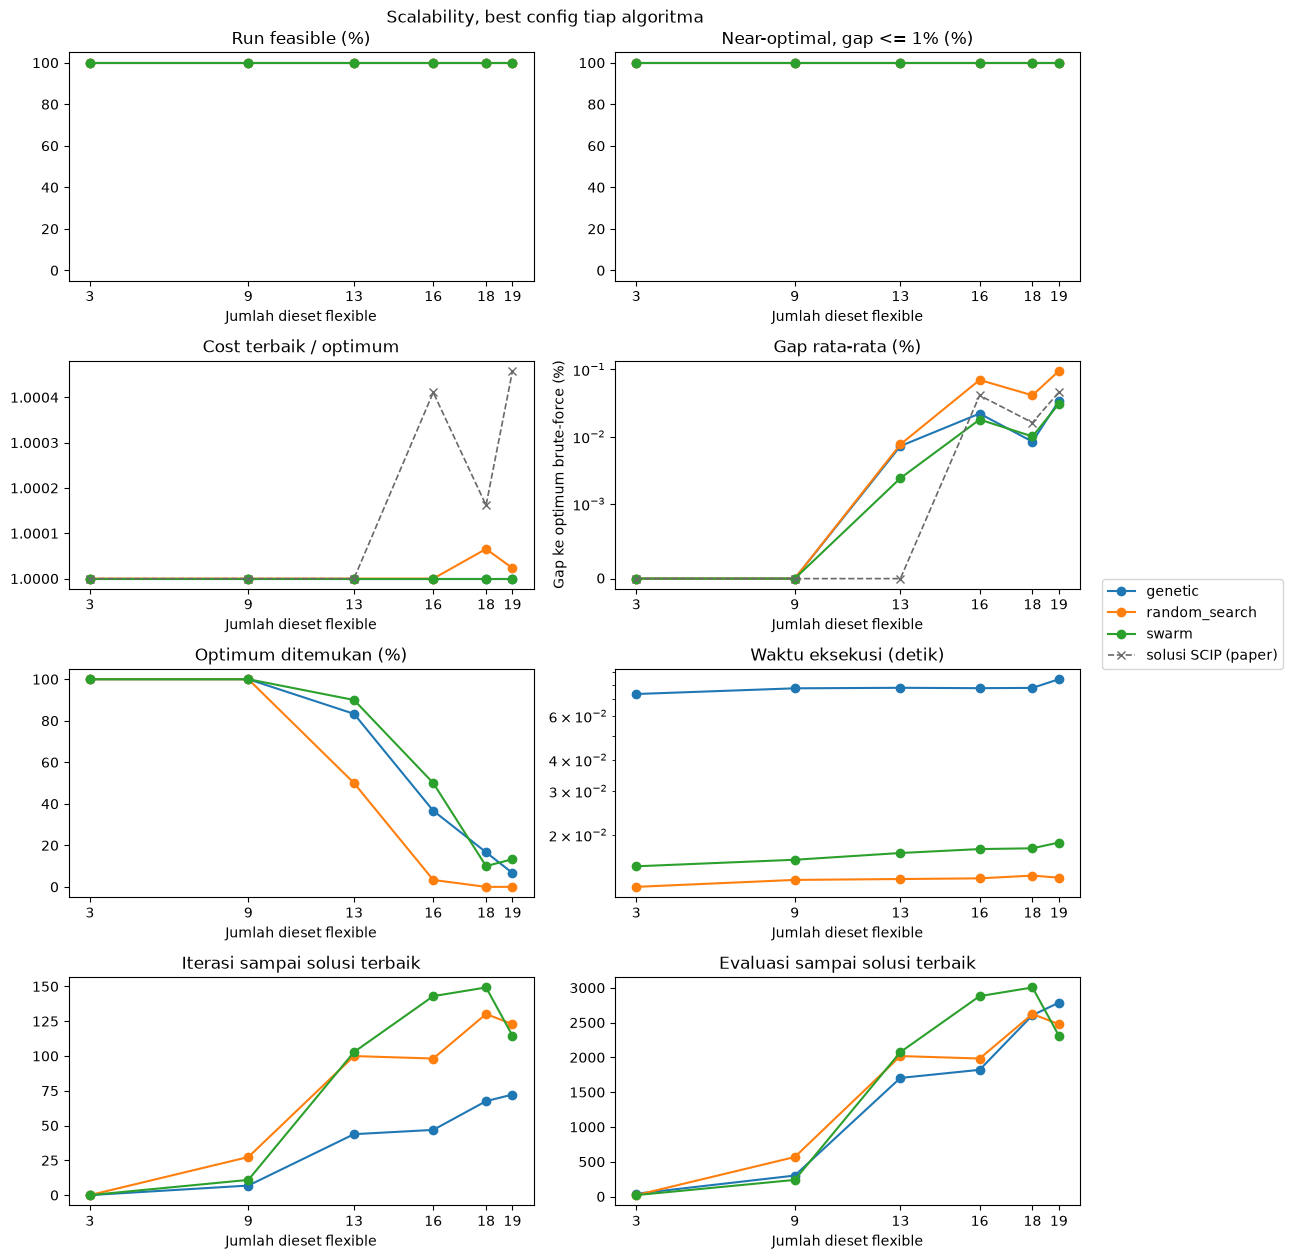

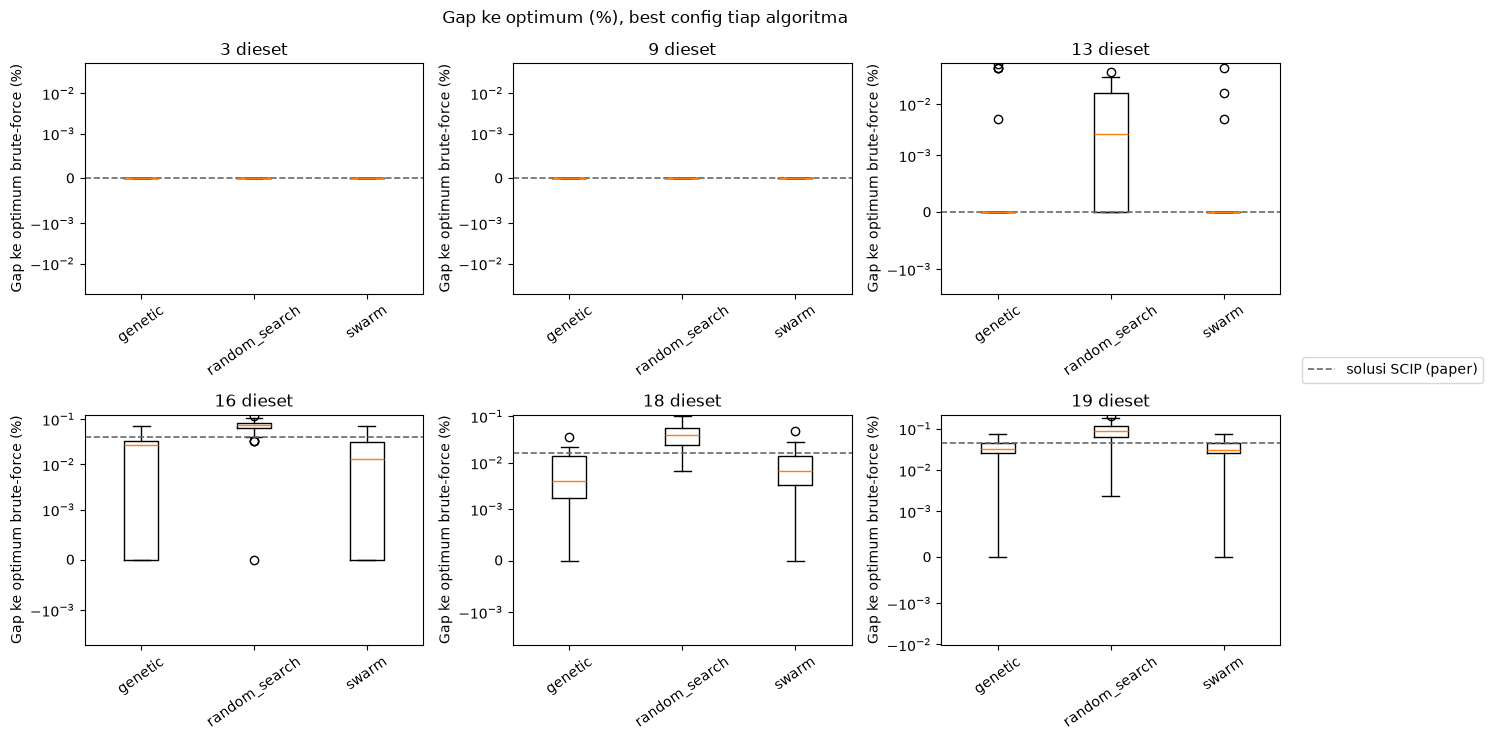

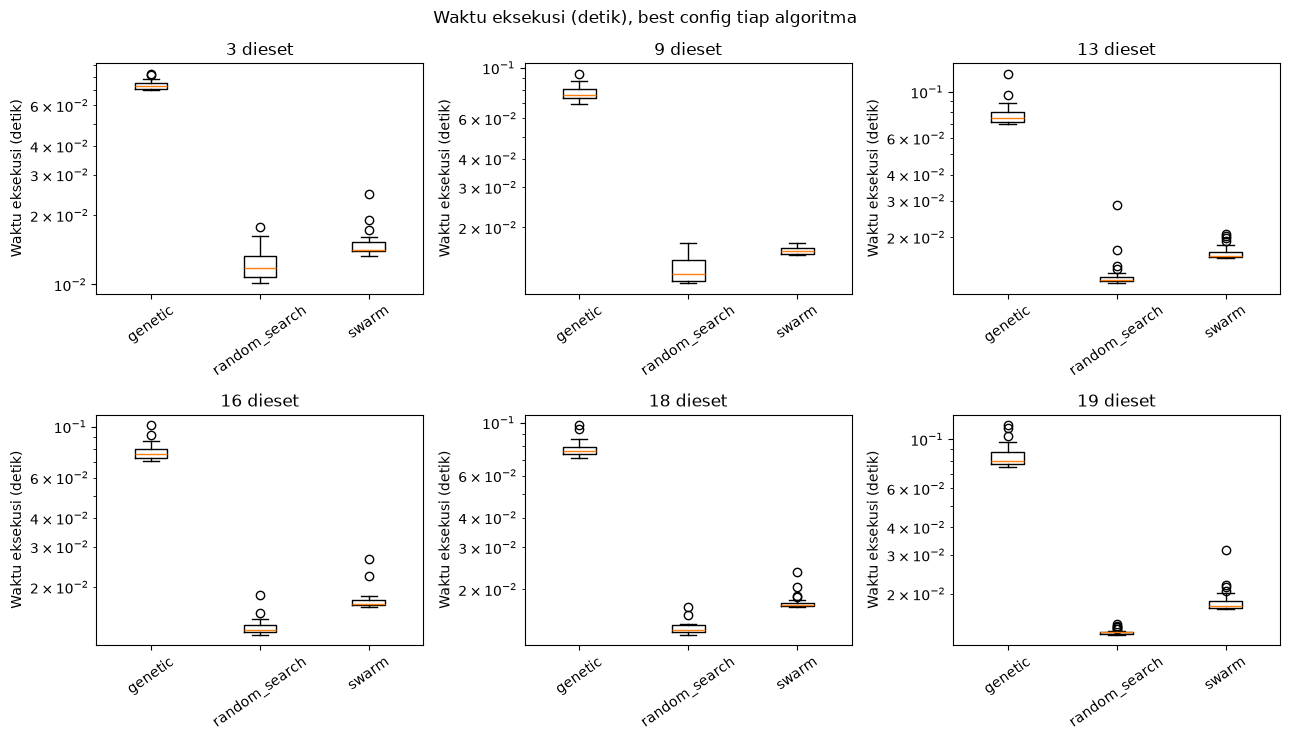

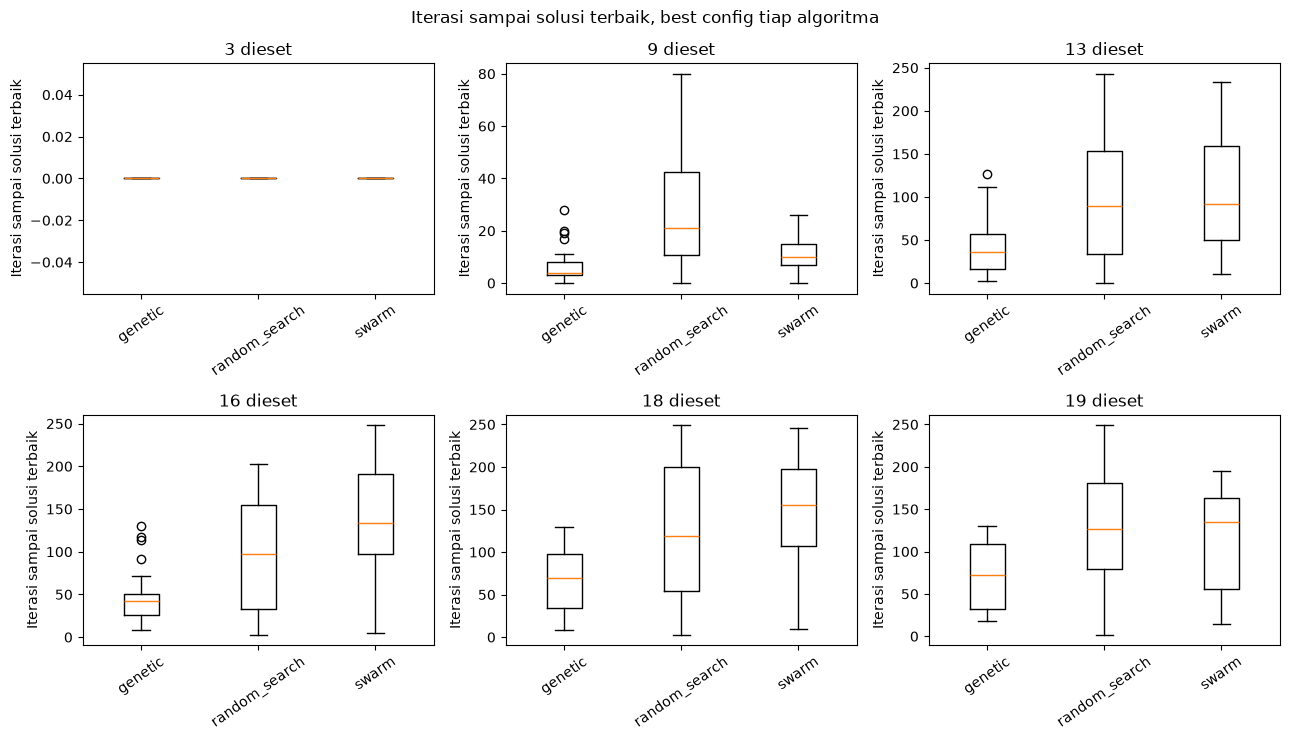

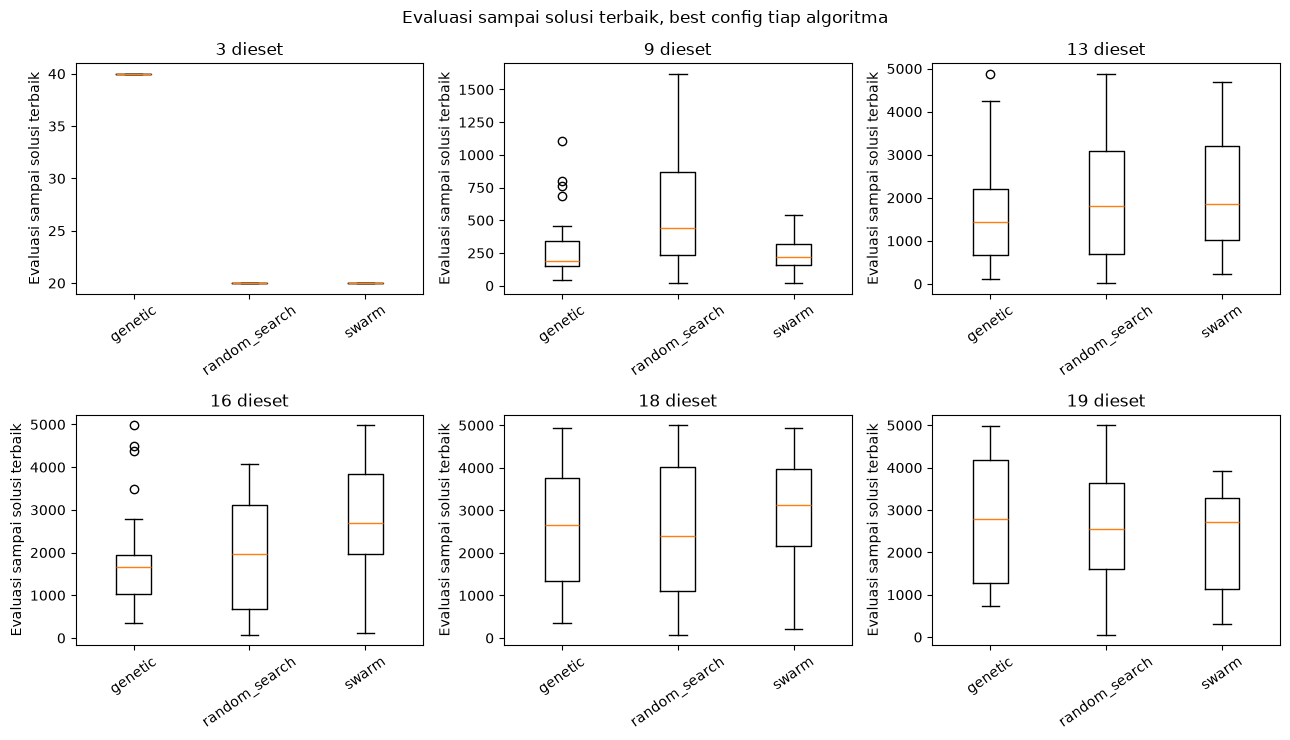

In [5]:
fig = plots.plot_group_convergence(best_results, instances, "algorithm", "Rata-rata konvergensi, best config tiap algoritma", OPTIMUM)
plots.save_figure(fig, figure_dir / "convergence.png")
plt.show()

fig = plots.plot_group_scalability(best_summary, "algorithm", "Scalability, best config tiap algoritma", OPTIMUM)
plots.save_figure(fig, figure_dir / "scalability.png")
plt.show()

for metric in ["gap_pct", "runtime_sec", "iterations_to_best", "evaluations_to_best"]:
    fig = plots.plot_group_distribution(best_runs, metric, "algorithm", f"{plots.LABELS[metric]}, best config tiap algoritma", OPTIMUM)
    plots.save_figure(fig, figure_dir / f"{metric}.png")
    plt.show()

## 5. Statistik dan uji signifikansi

Cost dan gap terbaik, rata-rata, simpangan baku, dan terburuk dari 30 run konfigurasi terbaik tiap algoritma. Setelah itu, gap akhir setiap pasangan algoritma dibandingkan per instance dengan uji Mann-Whitney U (nama lain Wilcoxon rank-sum), $\alpha = 0{,}05$. Uji ini dipakai karena distribusi gap tidak normal: banyak run bernilai tepat 0. Jika signifikan, algoritma dengan median gap lebih kecil dianggap lebih baik.

In [6]:
from src.evaluation.stats import cost_statistics, gap_statistics, pairwise_tests

gap_stats = gap_statistics(best_runs)
save_table(gap_stats, table_dir / "gap_statistics.csv")

gap_stats.pivot_table(index="n_diesets", columns="algorithm", values=["best", "mean", "std", "worst"]).round(4)

best                        mean                           std                         worst                      
algorithm genetic random_search swarm genetic random_search   swarm genetic random_search   swarm genetic random_search   swarm
n_diesets                                                                                                                      
3             0.0        0.0000   0.0  0.0000        0.0000  0.0000  0.0000        0.0000  0.0000  0.0000        0.0000  0.0000
9             0.0        0.0000   0.0  0.0000        0.0000  0.0000  0.0000        0.0000  0.0000  0.0000        0.0000  0.0000
13            0.0        0.0000   0.0  0.0072        0.0077  0.0024  0.0184        0.0110  0.0096  0.0598        0.0424  0.0508
16            0.0        0.0000   0.0  0.0220        0.0697  0.0180  0.0195        0.0238  0.0206  0.0710        0.1191  0.0694
18            0.0        0.0065   0.0  0.0084        0.0412  0.0101  0.0085        0.0208  0.0104  0.0360        0.1027  0.0490
19            0.0        0.0023   0.0  0.0338        0.0948  0.0308  0.0161        0.0439  0.0189  0.0737        0.2063  0.0737

In [7]:
cost_stats = cost_statistics(best_runs)
save_table(cost_stats, table_dir / "cost_statistics.csv")

cost_stats.pivot_table(index="n_diesets", columns="algorithm", values=["best", "mean", "std", "worst"]).round(2)

best                                  mean                                std                              worst                          
algorithm     genetic random_search       swarm     genetic random_search       swarm  genetic random_search    swarm     genetic random_search       swarm
n_diesets                                                                                                                                                  
3           443483.21     443483.21   443483.21   443483.21     443483.21   443483.21     0.00          0.00     0.00   443483.21     443483.21   443483.21
9          2249378.78    2249378.78  2249378.78  2249378.78    2249378.78  2249378.78     0.00          0.00     0.00  2249378.78    2249378.78  2249378.78
13         5223596.12    5223596.12  5223596.12  5223974.73    5223996.89  5223722.10   958.79        573.86   503.97  5226720.98    5225809.41  5226249.39
16         5801121.21    5801121.21  5801121.21  5802399.81    5805164.48  5802163.26  1131.78       1378.01  1197.45  5805242.11    5808028.91  5805146.57
18         5962911.99    5963302.42  5962911.99  5963414.78    5965369.04  5963512.82   508.44       1241.58   621.08  5965061.05    5969033.44  5965833.89
19         6112960.59    6113101.33  6112960.59  6115027.31    6118758.63  6114840.69   984.31       2683.04  1154.43  6117468.33    6125572.41  6117468.33

In [8]:
tests = pairwise_tests(best_runs)
save_table(tests, table_dir / "wilcoxon.csv")

tests.round({"median_a": 4, "median_b": 4, "p_value": 4})

,n_diesets,algorithm_a,algorithm_b,median_a,median_b,p_value,significant,better
0,3,genetic,random_search,0.0000,0.0000,1.0000,False,-
1,3,genetic,swarm,0.0000,0.0000,1.0000,False,-
2,3,random_search,swarm,0.0000,0.0000,1.0000,False,-
3,9,genetic,random_search,0.0000,0.0000,1.0000,False,-
4,9,genetic,swarm,0.0000,0.0000,1.0000,False,-
5,9,random_search,swarm,0.0000,0.0000,1.0000,False,-
6,13,genetic,random_search,0.0000,0.0026,0.0286,True,genetic
7,13,genetic,swarm,0.0000,0.0000,0.4087,False,-
8,13,random_search,swarm,0.0026,0.0000,0.0013,True,swarm
9,16,genetic,random_search,0.0264,0.0742,0.0000,True,genetic
